# import datasets

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

data = Path("../data/")

train = pd.read_csv(data / 'train.csv', parse_dates=['Date'], dtype={"StateHoliday": str})
store = pd.read_csv(data / 'store.csv')


# first exploration

In [17]:

trsh = train.shape
print('The train dataset has {trsh[0]} rows and {trsh[1]} columns'.format(trsh=trsh))
print(train.dtypes)
print(train.head(2))

print('')

stsh = store.shape
print('The store dataset has {stsh[0]} rows and {stsh[1]} columns'.format(stsh=stsh))
print(store.dtypes)
print(store.head(2))


The train dataset has 1017209 rows and 9 columns
Store                     int64
DayOfWeek                 int64
Date             datetime64[ns]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday             object
SchoolHoliday             int64
dtype: object
   Store  DayOfWeek       Date  Sales  Customers  Open  Promo StateHoliday  \
0      1          5 2015-07-31   5263        555     1      1            0   
1      2          5 2015-07-31   6064        625     1      1            0   

   SchoolHoliday  
0              1  
1              1  

The store dataset has 1115 rows and 10 columns
Store                          int64
StoreType                     object
Assortment                    object
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYe

The train dataset has 1017209 rows and 9 columns. \
The store dataset has 1115 rows and 10 columns.

In [18]:
df = train.merge(store, on="Store", how="left")
print(df.groupby('Open')['Sales'].mean())

print('')

close = df["Open"].eq(0).mean().round(2) * 100
print(f'There are {close}% of closed days')

Open
0       0.000000
1    6955.514291
Name: Sales, dtype: float64

There are 17.0% of closed days


There are 17.0% of closed days

# exploration by shop

942    934
758    180
941      1
Name: count, dtype: int64
There are 180 shops with less than 942 rows and 1 shop with 941 rows.

There are 184 missing days for shop 13, from 2014-07-01 00:00:00 to 2014-12-31 00:00:00
The gap in data for shop 13 is continuous between 2014-07-01 00:00:00 and 2014-12-31 00:00:00

There are 1 missing days for shop 988, from 2013-01-01 00:00:00 to 2013-01-01 00:00:00


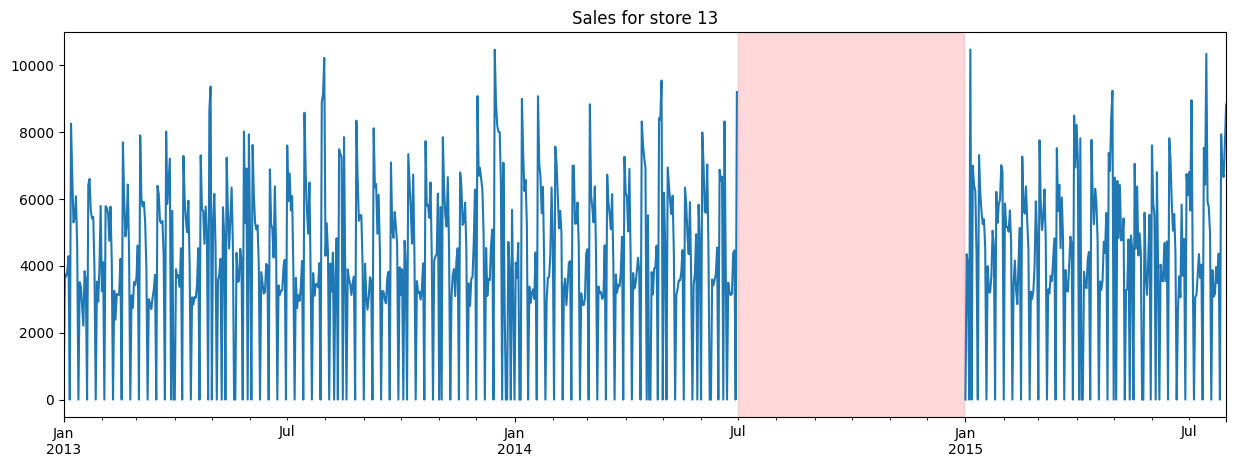

In [19]:
nb_rows_per_shop = df.groupby("Store").size().value_counts()
print(nb_rows_per_shop)

print(f'There are {nb_rows_per_shop.iloc[1]} shops with less than {nb_rows_per_shop.index[0]} rows and {nb_rows_per_shop.iloc[2]} shop with {nb_rows_per_shop.index[2]} rows.')
print('')

# Full calendar expected for every store
all_dates = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")

# shops with missing values
shop = df.groupby("Store")['Store'].value_counts()
shop941 = df[df['Store'] == shop[(shop == 941)].index[0]]
shop758 = df[df['Store'].isin(shop[(shop == 758)].index[:1])]

# Dates missing for one store
missing941 = all_dates.difference(shop941["Date"])
missing758 = all_dates.difference(shop758["Date"])
print(f'There are {len(missing758)} missing days for shop {shop758["Store"].iloc[0]}, from {missing758.min()} to {missing758.max()}')
print(f'The gap in data for shop {shop758["Store"].iloc[0]} is continuous between {missing758.min()} and {missing758.max()}')
print('')
print(f'There are {len(missing941)} missing days for shop {shop941["Store"].iloc[0]}, from {missing941.min()} to {missing941.max()}')

# visualisation for shop 13

s = shop758.set_index("Date")["Sales"].reindex(all_dates)  # missing days -> NaN

fig, ax = plt.subplots(figsize=(15, 5))
s.plot(ax=ax, title=f'Sales for store {shop758["Store"].iloc[0]}')
ax.axvspan(missing758.min(), missing758.max(), color="red", alpha=0.15)
plt.show()

There are 180 shops with less than 942 rows and 1 shop with 941 rows.

There are 184 missing days for shop 13, from 2014-07-01 00:00:00 to 2014-12-31 00:00:00
The gap in data for shop 13 is continuous between 2014-07-01 00:00:00 and 2014-12-31 00:00:00

There are 1 missing days for shop 988, from 2013-01-01 00:00:00 to 2013-01-01 00:00:00

Open
0    172817
1    844392
dtype: int64
There are 54 rows with open store and 0 sales and 41 unique stores with 0 sales these days.


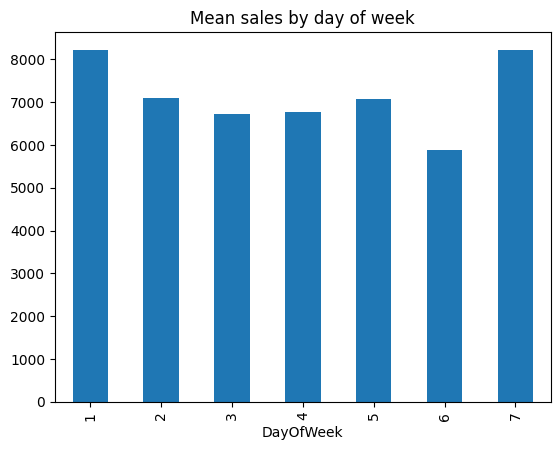

The are more sales on days 1 and 7 (Monday and Sunday) and less sales on days 6 (Saturday).


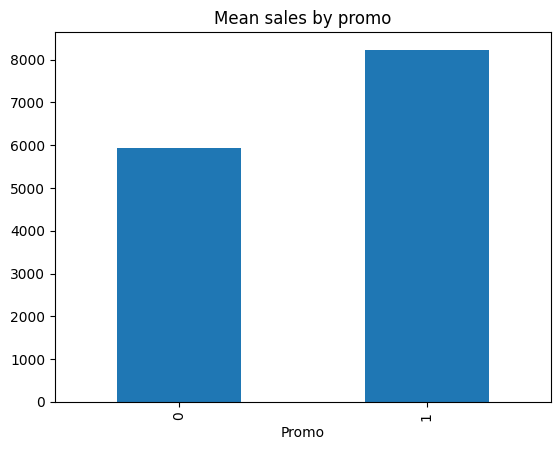

The are more sales on when promotion is active (1).
                   mean  size
StoreType                    
a           2912.109091  1100
b          11449.909296  2216
d           3520.267148   277
The majority of open shops on sundays are from type b
StoreType            a             b            c            d
DayOfWeek                                                     
1          8336.866386  11055.024831  7988.505038  7953.577311
2          7294.827873  10171.527379  6874.859536  6661.466135
3          6838.063616  10013.842908  6563.043038  6438.626952
4          6836.994358  10207.536771  6599.723199  6531.646842
5          6998.903980  10708.558942  6985.372428  7050.549688
6          5361.151112   8011.245598  6608.117410  6352.558554
7          2912.109091  11449.909296          NaN  3520.267148
Shops of type b have significantly more sales than a, c and d across the whole week. Therefore the higher sales we observe on sundays rather come from the quasi absence of the o

In [20]:
# Rows per Open value
print(df.groupby("Open").size())

# Open days with zero sales
open_zero = df[(df["Open"] == 1) & (df["Sales"] == 0)]
print(f'There are {len(open_zero)} rows with open store and 0 sales and {open_zero["Store"].nunique()} unique stores with 0 sales these days.')

d = df[df["Open"] == 1]

d.groupby("DayOfWeek")["Sales"].mean().plot(kind="bar", title="Mean sales by day of week")
plt.show()

print('The are more sales on days 1 and 7 (Monday and Sunday) and less sales on days 6 (Saturday).')

d.groupby("Promo")["Sales"].mean().plot(kind="bar", title="Mean sales by promo")
plt.show()

print('The are more sales on when promotion is active (1).')

# verification, why more sales on sunday??
print(d[d["DayOfWeek"] == 7].groupby("StoreType")["Sales"].agg(["mean", "size"]))
print(f'The majority of open shops on sundays are from type b')

print(d.groupby(["StoreType", "DayOfWeek"])["Sales"].mean().unstack(0))
print(f'Shops of type b have significantly more sales than a, c and d across the whole week. Therefore the higher sales we observe on sundays rather come from the quasi absence of the other shops rather than a sunday effect.')

There are 54 rows with open store and 0 sales and 41 unique stores with 0 sales these days. \
The are more sales on days 1 and 7 (Monday and Sunday) and less sales on days 6 (Saturday). \
The are more sales on when promotion is active (1). \
The majority of open shops on sundays are from type b \
Shops of type b have significantly more sales than a, c and d across the whole week. Therefore the higher sales we observe on sundays rather come from the quasi absence of the other shops rather than a sunday effect.

# Seasonality

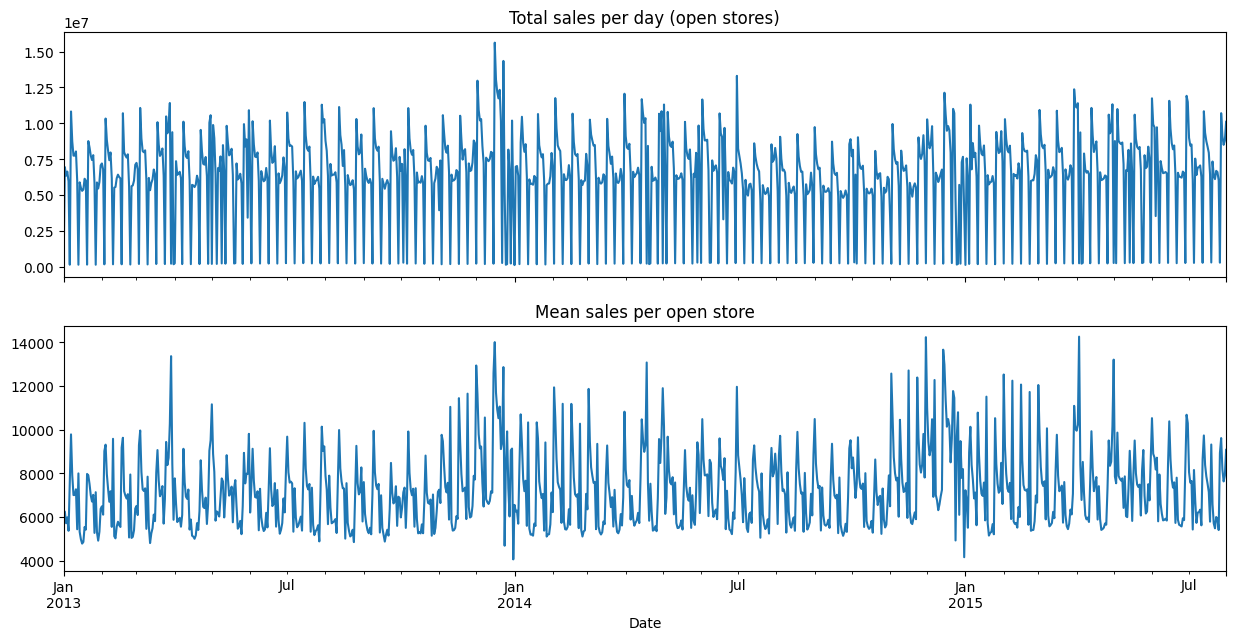

,mean,size
StateHoliday,,
0,6953.515034,843482
a,8487.471182,694
b,9887.889655,145
c,9743.746479,71


In [21]:
daily = df[df["Open"] == 1].groupby("Date")["Sales"].agg(total="sum", per_store="mean")

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
daily["total"].plot(ax=axes[0], title="Total sales per day (open stores)")
daily["per_store"].plot(ax=axes[1], title="Mean sales per open store")
plt.show()

d.groupby("StateHoliday")["Sales"].agg(["mean", "size"])

We can see seasonality with more sales around eatern (April) and christmas (December).

# load data

In [25]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

from src.data import load_data


df = load_data(only_open=False)
df.shape   # expect (1017209, 18)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


(1017209, 18)